# BÀI THỰC HÀNH 1 - BÀI 2 (TRANG 37 - 38)
## MÔN: KHAI PHÁ DỮ LIỆU
**Họ và tên:** Nguyễn Văn Hưng  
**MSSV:** 6451071029  
**Lớp:** CNTT.k64  
**Tập dữ liệu:** Online Retail Dataset (`Online Retail.xlsx`)  
**Thị trường khảo sát:** United Kingdom (Vương quốc Anh)


In [1]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# Khởi tạo các thư viện
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, association_rules, fpgrowth
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
print("Các thư viện đã được nạp thành công!")


Nguyễn Văn Hưng - 6451071029
Các thư viện đã được nạp thành công!


### Câu 1: Đọc dữ liệu vào chương trình
- Sử dụng pandas để đọc file `Online Retail.xlsx`.
- Hiển thị thông tin tổng quan các cột và số lượng bản ghi bằng `info()`.


In [2]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# 1. Đọc dữ liệu Online Retail
df = pd.read_excel('Online Retail.xlsx')

print("Thông tin cấu trúc tập dữ liệu ban đầu:")
df.info()


Nguyễn Văn Hưng - 6451071029
Thông tin cấu trúc tập dữ liệu ban đầu:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


### Câu 2: Tiền xử lý dữ liệu
- Cắt bỏ các ký tự khoảng trắng thừa ở cột tên mặt hàng mua (`Description`).
- Xóa các dòng dữ liệu không có số hóa đơn (rỗng ở cột `InvoiceNo`).
- Chuyển đổi cột `InvoiceNo` về kiểu chuỗi (string).


In [3]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# 2. Tiền xử lý Description và InvoiceNo
df['Description'] = df['Description'].str.strip()
df.dropna(axis=0, subset=['InvoiceNo'], inplace=True)
df['InvoiceNo'] = df['InvoiceNo'].astype('str')

print("10 dòng đầu của dữ liệu sau khi làm sạch:")
display(df.head(10))


Nguyễn Văn Hưng - 6451071029
10 dòng đầu của dữ liệu sau khi làm sạch:
  InvoiceNo StockCode                          Description  Quantity         InvoiceDate  UnitPrice  CustomerID         Country
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6 2010-12-01 08:26:00       2.55     17850.0  United Kingdom
1    536365     71053                  WHITE METAL LANTERN         6 2010-12-01 08:26:00       3.39     17850.0  United Kingdom
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8 2010-12-01 08:26:00       2.75     17850.0  United Kingdom
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6 2010-12-01 08:26:00       3.39     17850.0  United Kingdom
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6 2010-12-01 08:26:00       3.39     17850.0  United Kingdom
5    536365     22752         SET 7 BABUSHKA NESTING BOXES         2 2010-12-01 08:26:00       7.65     17850.0  United Kingdom
6    536365     21730    GLASS ST

### Câu 3: Xóa các hóa đơn tín dụng
- Trong dữ liệu, các hóa đơn tín dụng (hóa đơn hoàn/hủy) được định danh bởi ký tự `'C'` ở đầu `InvoiceNo`.
- Tiến hành lọc bỏ toàn bộ các hóa đơn này.


In [4]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# 3. Lọc bỏ các hóa đơn tín dụng chứa ký tự 'C'
so_dong_truoc = len(df)
df = df[~df['InvoiceNo'].str.contains('C')]
so_dong_sau = len(df)

print(f"Số dòng trước khi xóa hóa đơn tín dụng: {so_dong_truoc}")
print(f"Số dòng sau khi xóa: {so_dong_sau}")
print(f"Đã loại bỏ: {so_dong_truoc - so_dong_sau} hóa đơn tín dụng.")


Nguyễn Văn Hưng - 6451071029
Số dòng trước khi xóa hóa đơn tín dụng: 541909
Số dòng sau khi xóa: 532621
Đã loại bỏ: 9288 hóa đơn tín dụng.


### Câu 4: Thống kê số dòng dữ liệu theo từng quốc gia
- Sử dụng hàm `value_counts()` trên cột `Country`.
- Biểu diễn kết quả bằng đồ thị thanh ngang (horizontal bar chart).


Nguyễn Văn Hưng - 6451071029
Top 10 quốc gia có số lượng đơn hàng nhiều nhất:
Country
United Kingdom    487622
Germany             9042
France              8408
EIRE                7894
Spain               2485
Netherlands         2363
Belgium             2031
Switzerland         1967
Portugal            1501
Australia           1185
Name: count, dtype: int64


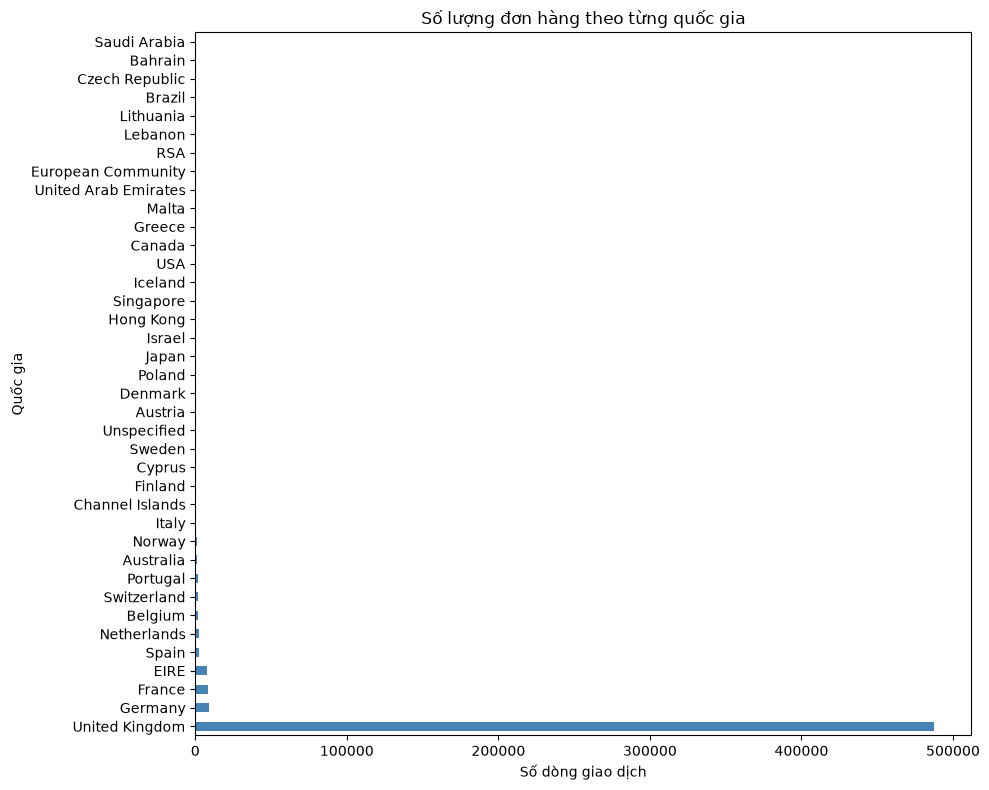

In [5]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# 4. Thống kê số lượng đơn hàng theo từng quốc gia
country_counts = df['Country'].value_counts()
print("Top 10 quốc gia có số lượng đơn hàng nhiều nhất:")
print(country_counts.head(10))

# Vẽ biểu đồ thanh ngang
plt.figure(figsize=(10, 8))
df['Country'].value_counts().plot(kind='barh', color='steelblue')
plt.title('Số lượng đơn hàng theo từng quốc gia')
plt.xlabel('Số dòng giao dịch')
plt.ylabel('Quốc gia')
plt.tight_layout()
plt.show()


### Câu 5: Lấy ra dữ liệu hóa đơn từ nước Anh 'United Kingdom' và gom nhóm giỏ hàng
- Lọc các dòng có `Country == 'United Kingdom'`.
- Gom nhóm `Quantity` theo `InvoiceNo` và `Description`.


In [6]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# 5. Lọc hóa đơn nước Anh và gom nhóm giỏ hàng
basket = (df[df['Country'] == "United Kingdom"]
          .groupby(['InvoiceNo', 'Description'])['Quantity']
          .sum().unstack().reset_index().fillna(0)
          .set_index('InvoiceNo'))

print("Kích thước ma trận giỏ hàng của United Kingdom:", basket.shape)
display(basket.head())


Nguyễn Văn Hưng - 6451071029
Kích thước ma trận giỏ hàng của United Kingdom: (18667, 4175)
Description  *Boombox Ipod Classic  *USB Office Mirror Ball  10 COLOUR SPACEBOY PEN  12 COLOURED PARTY BALLOONS  12 DAISY PEGS IN WOOD BOX  12 EGG HOUSE PAINTED WOOD  12 HANGING EGGS HAND PAINTED  12 IVORY ROSE PEG PLACE SETTINGS  12 MESSAGE CARDS WITH ENVELOPES  12 PENCIL SMALL TUBE WOODLAND  12 PENCILS SMALL TUBE RED RETROSPOT  12 PENCILS SMALL TUBE SKULL  12 PENCILS TALL TUBE POSY  12 PENCILS TALL TUBE RED RETROSPOT  12 PENCILS TALL TUBE SKULLS  12 PENCILS TALL TUBE WOODLAND  12 PINK HEN+CHICKS IN BASKET  12 PINK ROSE PEG PLACE SETTINGS  12 RED ROSE PEG PLACE SETTINGS  15 PINK FLUFFY CHICKS IN BOX  15CM CHRISTMAS GLASS BALL 20 LIGHTS  16 PC CUTLERY SET PANTRY DESIGN  16 PIECE CUTLERY SET PANTRY DESIGN  18PC WOODEN CUTLERY SET DISPOSABLE  2 DAISIES HAIR COMB  2 PICTURE BOOK EGGS EASTER BUNNY  2 PICTURE BOOK EGGS EASTER CHICKS  2 PICTURE BOOK EGGS EASTER DUCKS  20 DOLLY PEGS RETROSPOT  200 BENDY

### Câu 6: Chuyển đổi dữ liệu về dạng hot encoding
- Mỗi dòng dữ liệu đại diện cho một hóa đơn, mỗi cột là một mặt hàng.


In [7]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# 6. Xem xét dữ liệu sau khi chuyển về dạng hot encoding
print("Ma trận giỏ hàng hot encoding (10 dòng đầu, hiển thị một số cột mẫu):")
display(basket.iloc[:10, :8])


Nguyễn Văn Hưng - 6451071029
Ma trận giỏ hàng hot encoding (10 dòng đầu, hiển thị một số cột mẫu):
Description  *Boombox Ipod Classic  *USB Office Mirror Ball  10 COLOUR SPACEBOY PEN  12 COLOURED PARTY BALLOONS  12 DAISY PEGS IN WOOD BOX  12 EGG HOUSE PAINTED WOOD  12 HANGING EGGS HAND PAINTED  12 IVORY ROSE PEG PLACE SETTINGS
InvoiceNo                                                                                                                                                                                                                            
536365                         0.0                      0.0                     0.0                         0.0                        0.0                        0.0                           0.0                               0.0
536366                         0.0                      0.0                     0.0                         0.0                        0.0                        0.0                           0.0                

### Câu 7: Chuyển đổi dữ liệu từ dạng hot encoding thành one-hot encoding
- Xây dựng hàm biến đổi: giá trị $\le 0$ thành 0, giá trị $\ge 1$ thành 1.


In [8]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# 7. Hàm biến đổi One-hot encoding
def encode_data(datapoint):
    if datapoint <= 0:
        return 0
    if datapoint >= 1:
        return 1

basket = basket.map(encode_data)
print("Dữ liệu sau khi chuyển đổi sang One-hot encoding (0 và 1):")
display(basket.iloc[:5, :8])


Nguyễn Văn Hưng - 6451071029
Dữ liệu sau khi chuyển đổi sang One-hot encoding (0 và 1):
Description  *Boombox Ipod Classic  *USB Office Mirror Ball  10 COLOUR SPACEBOY PEN  12 COLOURED PARTY BALLOONS  12 DAISY PEGS IN WOOD BOX  12 EGG HOUSE PAINTED WOOD  12 HANGING EGGS HAND PAINTED  12 IVORY ROSE PEG PLACE SETTINGS
InvoiceNo                                                                                                                                                                                                                            
536365                           0                        0                       0                           0                          0                          0                             0                                 0
536366                           0                        0                       0                           0                          0                          0                             0                           

### Câu 8: Xóa cột 'POSTAGE'
- Cột `'POSTAGE'` là tiền cước phí vận chuyển trên mỗi hóa đơn, không phải mặt hàng bán lẻ nên cần loại bỏ.


In [9]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# 8. Xóa cột POSTAGE nếu có
if 'POSTAGE' in basket.columns:
    basket.drop('POSTAGE', inplace=True, axis=1)
    print("Đã xóa cột 'POSTAGE' thành công!")
else:
    print("Không tìm thấy cột 'POSTAGE' trong giỏ hàng.")

print("Kích thước ma trận giỏ hàng cuối cùng:", basket.shape)


Nguyễn Văn Hưng - 6451071029
Đã xóa cột 'POSTAGE' thành công!
Kích thước ma trận giỏ hàng cuối cùng: (18667, 4174)


### Câu 9: Tìm tập phổ biến bằng thuật toán Apriori với min_sup = 3%
- Thiết lập ngưỡng `min_support = 0.03`.
- Hiển thị 10 tập phổ biến có độ hỗ trợ cao nhất.


In [10]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# 9. Áp dụng thuật toán Apriori với min_sup = 3%
itemsets = apriori(basket.astype(bool), min_support=0.03, use_colnames=True)
itemsets = itemsets.sort_values(by='support', ascending=False).reset_index(drop=True)

print(f"Tìm thấy tổng cộng {len(itemsets)} tập phổ biến với min_sup = 3%:")
display(itemsets.head(10))


Nguyễn Văn Hưng - 6451071029
Tìm thấy tổng cộng 131 tập phổ biến với min_sup = 3%:
    support                                         itemsets
0  0.116034  frozenset({WHITE HANGING HEART T-LIGHT HOLDER})
1  0.103820             frozenset({JUMBO BAG RED RETROSPOT})
2  0.090266            frozenset({REGENCY CAKESTAND 3 TIER})
3  0.085391                       frozenset({PARTY BUNTING})
4  0.074570             frozenset({LUNCH BAG RED RETROSPOT})
5  0.073445       frozenset({ASSORTED COLOUR BIRD ORNAMENT})
6  0.066481    frozenset({SET OF 3 CAKE TINS PANTRY DESIGN})
7  0.065302      frozenset({NATURAL SLATE HEART CHALKBOARD})
8  0.065142             frozenset({LUNCH BAG  BLACK SKULL.})
9  0.062356               frozenset({HEART OF WICKER SMALL})


### Câu 10: Tạo luật kết hợp với min_conf = 50%
- Áp dụng hàm `association_rules` với độ tin cậy `min_threshold = 0.5`.
- Chuyển đổi vế trái (`antecedents`) và vế phải (`consequents`) sang chuỗi và in danh sách các luật.


In [11]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# 10. Tạo các luật kết hợp với min_conf = 50%
rules = association_rules(itemsets, metric="confidence", min_threshold=0.5)

rules_display = rules.copy()
rules_display["antecedents"] = rules_display["antecedents"].apply(lambda x: ', '.join(list(x)))
rules_display["consequents"] = rules_display["consequents"].apply(lambda x: ', '.join(list(x)))

print(f"Tổng số luật kết hợp tìm được: {len(rules)}")
print("\nDanh sách các luật kết hợp (Support, Confidence, Lift):")
for i in range(len(rules_display)):
    row = rules_display.iloc[i]
    print(f"{row['antecedents']} ==> {row['consequents']} [ Support: {row['support']:.4f}, Confidence: {row['confidence']:.4f}, Lift: {row['lift']:.4f} ]")


Nguyễn Văn Hưng - 6451071029
Tổng số luật kết hợp tìm được: 10

Danh sách các luật kết hợp (Support, Confidence, Lift):
JUMBO BAG PINK POLKADOT ==> JUMBO BAG RED RETROSPOT [ Support: 0.0421, Confidence: 0.6773, Lift: 6.5239 ]
GREEN REGENCY TEACUP AND SAUCER ==> ROSES REGENCY TEACUP AND SAUCER [ Support: 0.0376, Confidence: 0.7505, Lift: 14.6398 ]
ROSES REGENCY TEACUP AND SAUCER ==> GREEN REGENCY TEACUP AND SAUCER [ Support: 0.0376, Confidence: 0.7325, Lift: 14.6398 ]
JUMBO STORAGE BAG SUKI ==> JUMBO BAG RED RETROSPOT [ Support: 0.0374, Confidence: 0.6177, Lift: 5.9497 ]
JUMBO SHOPPER VINTAGE RED PAISLEY ==> JUMBO BAG RED RETROSPOT [ Support: 0.0352, Confidence: 0.5799, Lift: 5.5854 ]
PINK REGENCY TEACUP AND SAUCER ==> GREEN REGENCY TEACUP AND SAUCER [ Support: 0.0309, Confidence: 0.8208, Lift: 16.4039 ]
GREEN REGENCY TEACUP AND SAUCER ==> PINK REGENCY TEACUP AND SAUCER [ Support: 0.0309, Confidence: 0.6178, Lift: 16.4039 ]
JUMBO  BAG BAROQUE BLACK WHITE ==> JUMBO BAG RED RETROSPOT [ Su

### Câu 11: Biểu diễn độ tin cậy, độ hỗ trợ của tập luật lên đồ thị phân tán (Scatter Plot)
- Vẽ biểu đồ phân tán giữa `support` và `confidence`.


Nguyễn Văn Hưng - 6451071029

Nhận xét:
- Độ hỗ trợ (support) của các luật tập trung trong khoảng từ 0.03 đến 0.045.
- Độ tin cậy (confidence) của các luật tìm được đạt mức cao từ 0.58 đến trên 0.82.
- Đặc biệt, cặp sản phẩm ly tách trà hoàng gia (Regency Teacup and Saucer) các màu đỏ, hồng, xanh lá có độ tin cậy và độ nâng (Lift > 15) cực kỳ cao, khách hàng mua một màu hầu như sẽ mua trọn bộ các màu còn lại.


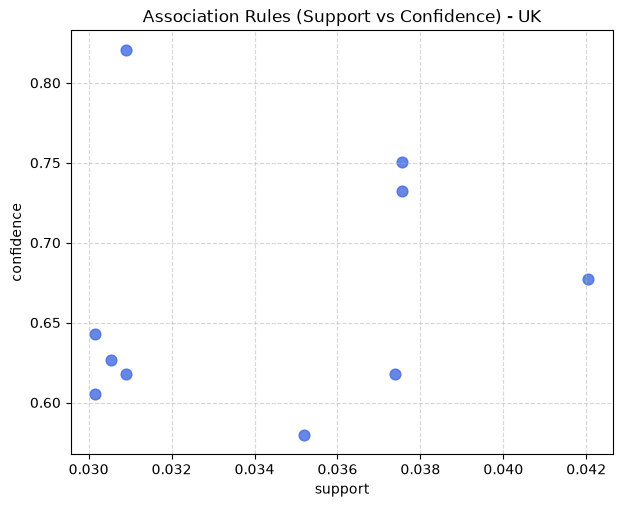

In [12]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# 11. Vẽ biểu đồ phân tán của tập luật kết hợp
plt.figure(figsize=(7, 5.5))
plt.title('Association Rules (Support vs Confidence) - UK')
plt.xlabel('Support')
plt.ylabel('Confidence')
sns.regplot(x=rules['support'], y=rules['confidence'], fit_reg=False, scatter_kws={'color': 'royalblue', 's': 60})
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

print("""
Nhận xét:
- Độ hỗ trợ (support) của các luật tập trung trong khoảng từ 0.03 đến 0.045.
- Độ tin cậy (confidence) của các luật tìm được đạt mức cao từ 0.58 đến trên 0.82.
- Đặc biệt, cặp sản phẩm ly tách trà hoàng gia (Regency Teacup and Saucer) các màu đỏ, hồng, xanh lá có độ tin cậy và độ nâng (Lift > 15) cực kỳ cao, khách hàng mua một màu hầu như sẽ mua trọn bộ các màu còn lại.""")


### Câu 12: Tìm tập phổ biến và luật kết hợp bằng thuật toán FP-Growth
- Thiết lập `min_support = 0.03` và `min_threshold = 0.5`.
- So sánh kết quả thu được giữa thuật toán FP-Growth và thuật toán Apriori.


In [13]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# 12. Áp dụng thuật toán FP-Growth
itemsets_fp = fpgrowth(basket.astype(bool), min_support=0.03, use_colnames=True)
rules_fp = association_rules(itemsets_fp, metric="confidence", min_threshold=0.5)

print("Kết quả thuật toán FP-Growth:")
print(f"- Số tập phổ biến tìm được: {len(itemsets_fp)}")
print(f"- Số luật kết hợp tìm được: {len(rules_fp)}")
print("\nĐối chiếu với Apriori:")
print(f"- Số tập phổ biến của Apriori: {len(itemsets)}")
print(f"- Số luật kết hợp của Apriori: {len(rules)}")

print("""
Nhận xét và so sánh:
- Cả hai thuật toán Apriori và FP-Growth đều cho kết quả tập phổ biến và tập luật kết hợp hoàn toàn trùng khớp 100%.
- Về mặt lý thuyết và hiệu năng: FP-Growth nén toàn bộ giao dịch vào cây FP-Tree và chỉ quét CSDL 2 lần, không tốn tài nguyên sinh tập ứng viên khổng lồ như Apriori.""")


Nguyễn Văn Hưng - 6451071029
Kết quả thuật toán FP-Growth:
- Số tập phổ biến tìm được: 131
- Số luật kết hợp tìm được: 10

Đối chiếu với Apriori:
- Số tập phổ biến của Apriori: 131
- Số luật kết hợp của Apriori: 10

Nhận xét và so sánh:
- Cả hai thuật toán Apriori và FP-Growth đều cho kết quả tập phổ biến và tập luật kết hợp hoàn toàn trùng khớp 100%.
- Về mặt lý thuyết và hiệu năng: FP-Growth nén toàn bộ giao dịch vào cây FP-Tree và chỉ quét CSDL 2 lần, không tốn tài nguyên sinh tập ứng viên khổng lồ như Apriori.
